# 3-D Hexagon Columns Map (pydeck)

**Family:** Spatial &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Spatial:* Use when precise locations or geographic patterns matter more than anything else.

## Design purpose

An interactive WebGL map that bins point locations into hexagons and extrudes each one into a column whose height and color show the count. The reader can tilt, rotate and zoom, so dense hot spots stand out as towers while the overall layout stays recognisable. The static preview shows the same aggregation as a 3-D bar chart.

## When to use

- Explore very dense point data interactively (tens of thousands to millions of points)
- Make hot spots pop out in presentations or exploratory sessions
- Put the result in a web page, where readers can rotate and hover for counts

## Avoid when

- Readers need to compare heights precisely (3-D perspective distorts them; use a flat hexbin map)
- The output is printed or static (tall columns hide the ones behind them)
- The reader's browser has no WebGL (some locked-down corporate machines)

## Alternatives

- Hexagonal grid map (flat hexbin)
- Choropleth
- Bubble map

## Design tips

- Encode the count twice (height and one-hue color) so it still reads from a top-down view
- Start from a moderate pitch (40–50°) and give readers the tooltip for exact values
- Use map_style=None (no basemap, no token) or a free basemap; Mapbox styles need an API key
- Needs a browser with WebGL and an internet connection (deck.gl loads from a CDN)

## Example

15,000 simulated ride-hailing pick-ups around a city centre, made of a dense core, two transit hubs and a scatter of background trips. The interactive page uses pydeck's HexagonLayer with a 300 m radius. The PNG preview is a matplotlib 3-D bar chart of the same data on a square grid.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(12)
lat0, lon0 = 40.0, -75.0                     # a generic mid-latitude city; no basemap is used
km_lat, km_lon = 1 / 111.0, 1 / (111.0 * np.cos(np.radians(lat0)))
hot = [(0.0, 0.0, 1.2, 0.45), (3.5, 2.0, 0.5, 0.15), (-4.0, -2.5, 0.6, 0.12)]  # (x km, y km, spread, share)
xs, ys = [], []
n = 15000
for x, y, s, share in hot:
    k = int(n * share)
    xs.append(rng.normal(x, s, k))
    ys.append(rng.normal(y, s, k))
k = n - sum(int(n * h[3]) for h in hot)
xs.append(rng.uniform(-8, 8, k))
ys.append(rng.uniform(-6, 6, k))
x_km, y_km = np.concatenate(xs), np.concatenate(ys)
df = pd.DataFrame({"lon": lon0 + x_km * km_lon, "lat": lat0 + y_km * km_lat, "x_km": x_km, "y_km": y_km})
df.head()

,lon,lat,x_km,y_km
0,-75.000096,40.009639,-0.008192,1.069966
1,-74.985236,39.989511,1.255372,-1.164305
2,-74.989534,39.985107,0.889906,-1.653098
3,-74.989783,40.020002,0.868748,2.220255
4,-74.977155,39.997656,1.942531,-0.260204


### Plot

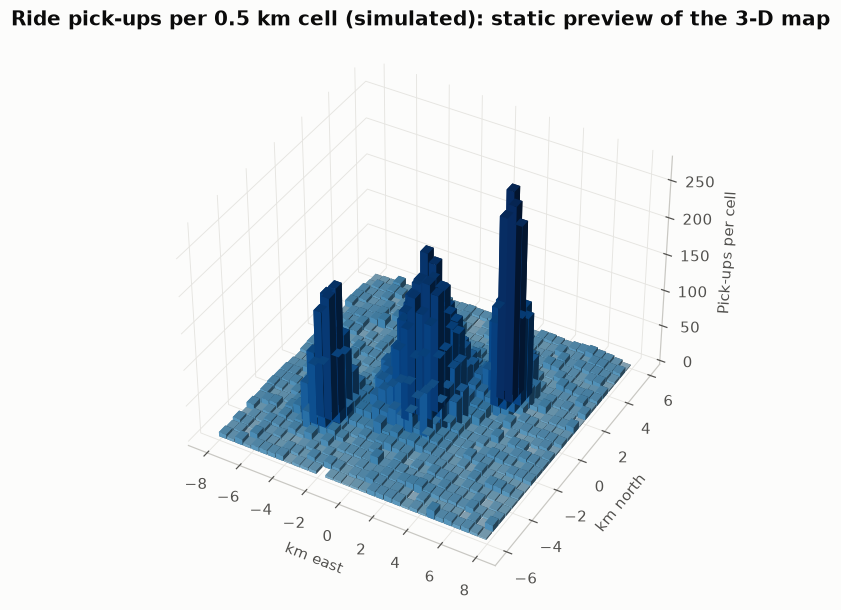

In [3]:
# Static preview: the same aggregation idea on a 0.5 km square grid, drawn as 3-D bars
counts, xe, ye = np.histogram2d(df["x_km"], df["y_km"], bins=[32, 24], range=[[-8, 8], [-6, 6]])
X, Y = np.meshgrid(xe[:-1], ye[:-1], indexing="ij")
mask = counts.ravel() > 0
h = counts.ravel()[mask]
colors = plt.get_cmap(SEQ_CMAP)(0.25 + 0.75 * np.log1p(h) / np.log1p(h.max()))
fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(projection="3d")
ax.bar3d(X.ravel()[mask], Y.ravel()[mask], 0, 0.45, 0.45, h, color=colors, shade=True,
         edgecolor="none")
ax.view_init(elev=38, azim=-60)
ax.set_xlabel("km east")
ax.set_ylabel("km north")
ax.set_zlabel("Pick-ups per cell")
ax.set_title("Ride pick-ups per 0.5 km cell (simulated): static preview of the 3-D map")
ax.xaxis.pane.set_alpha(0)
ax.yaxis.pane.set_alpha(0)
ax.zaxis.pane.set_alpha(0)
plt.show()

### Interactive version

The same data as a standalone interactive page (also saved next to the script as an `.html` file).

In [4]:
import pydeck as pdk

blues = [[205, 226, 251], [158, 197, 244], [109, 167, 236], [57, 135, 229], [37, 106, 191], [16, 66, 129]]
layer = pdk.Layer(
    "HexagonLayer", data=df[["lon", "lat"]], get_position=["lon", "lat"],
    radius=300, elevation_scale=6, elevation_range=[0, 1000], extruded=True,
    coverage=0.9, pickable=True, color_range=blues,
)
view = pdk.ViewState(latitude=lat0, longitude=lon0, zoom=11.3, pitch=48, bearing=-25)
deck = pdk.Deck(layers=[layer], initial_view_state=view, map_style=None,
                tooltip={"text": "{elevationValue} pick-ups"})
html = deck.to_html(as_string=True)
import html as _html
from IPython.display import HTML
HTML(f'<iframe srcdoc="{_html.escape(html)}" width="100%" height="560" style="border:0"></iframe>')

/Users/chenyuyu/work/visualization_library/.venv/lib/python3.12/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## How to read it

The tallest, darkest columns are the city centre and the two transit hubs. Tilt the interactive map to compare tower heights, or hover a column for its exact count. The low, pale columns around the edges are background trips.

---
Standalone script: [`pydeck_3d_columns.py`](pydeck_3d_columns.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)